<a href="https://colab.research.google.com/github/mazenkoz/artificial-intelligence-coursework/blob/flowers-travel-update/Task1_ImageClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CN6005 – Task 1: Multiclass Image Classification (ANN vs CNN)
**Dataset:** Flowers "Five Classes" (Kaggle, lara311) – https://www.kaggle.com/datasets/lara311/flowers-five-classes

We compare an ANN and a CNN for classifying five types of flower. Sections follow the brief (1.1–1.4); the full explanations are in the report (sections 2.1–2.6).

### Setup
Import the libraries, fix the random seed (42) and create a `screenshots/` folder for the figures.

In [ ]:
import os, time, random, pathlib, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs("screenshots", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (running on CPU)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1.1 Data Preparation and Exploration

### 1.1.1 Load and inspect the dataset
Download the dataset with KaggleHub and check how the folders are organised.

In [ ]:
# Download the dataset with kagglehub (or use a local copy if DATA_DIR is set)
path = os.environ.get("DATA_DIR")
if path is None:
    import kagglehub
    path = kagglehub.dataset_download("lara311/flowers-five-classes")
print("Path to dataset files:", path)

# Print the folder layout and how many files are in each folder
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 3:
        print("    " * depth + f"{os.path.basename(root) or root}/  ({len(files)} files)")

100%|██████████| 158M/158M [00:08<00:00, 20.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/lara311/flowers-five-classes/versions/1
1/  (0 files)
    train/  (0 files)
        daisy/  (501 files)
        rose/  (497 files)
        tulip/  (607 files)
        dandelion/  (646 files)
        sunflower/  (495 files)


### 1.1.2 Organise and clean
Build a table of image paths and labels, then remove corrupt images and exact duplicates.

Image files found: 2746
Broken images removed: 0
Images involved in duplication: 6 | groups: 3
Duplicate groups with DIFFERENT labels: 1


,path,label,md5
2517,/root/.cache/kagglehub/datasets/lara311/flower...,sunflower,6e42be87cdcb56a3d86a8f10ec3dc724
2698,/root/.cache/kagglehub/datasets/lara311/flower...,sunflower,6e42be87cdcb56a3d86a8f10ec3dc724
770,/root/.cache/kagglehub/datasets/lara311/flower...,rose,75a3d8ee9f189811e3c1b1730ff7e1f5
1338,/root/.cache/kagglehub/datasets/lara311/flower...,tulip,75a3d8ee9f189811e3c1b1730ff7e1f5
2412,/root/.cache/kagglehub/datasets/lara311/flower...,sunflower,c2c25e7d56294d6463c925adbf3df3e4
2486,/root/.cache/kagglehub/datasets/lara311/flower...,sunflower,c2c25e7d56294d6463c925adbf3df3e4


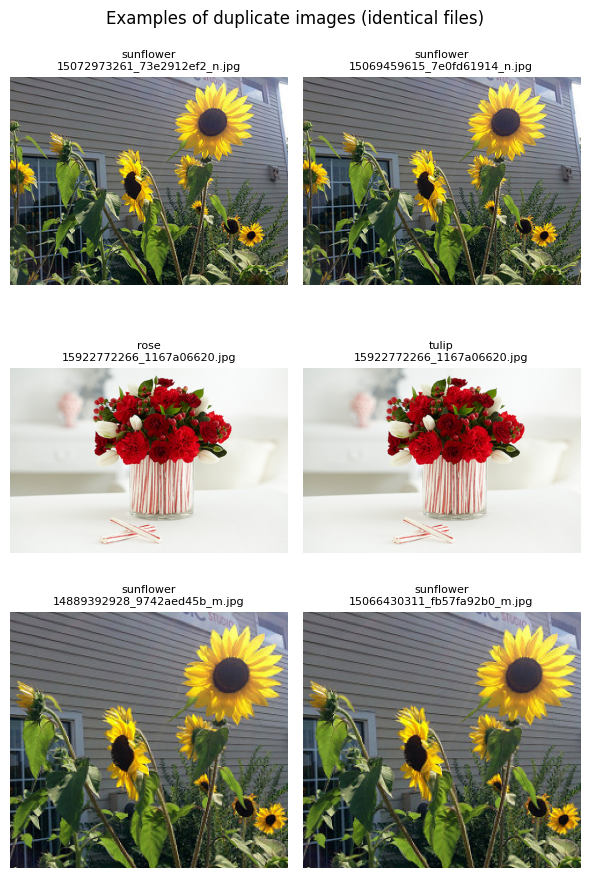

Duplicates removed: 3

Clean images: 2743
Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


,path,label,y
0,/root/.cache/kagglehub/datasets/lara311/flower...,daisy,0
1,/root/.cache/kagglehub/datasets/lara311/flower...,daisy,0
2,/root/.cache/kagglehub/datasets/lara311/flower...,daisy,0
3,/root/.cache/kagglehub/datasets/lara311/flower...,daisy,0
4,/root/.cache/kagglehub/datasets/lara311/flower...,daisy,0


In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

# 1) Build a table: one row per image -> (file path, label)
records = []
for root, dirs, files in os.walk(path):
    for f in files:
        if pathlib.Path(f).suffix.lower() in IMG_EXT:          # only keep image files
            label = pathlib.Path(root).name.strip().lower()     # parent folder = class name
            records.append((os.path.join(root, f), label))
df = pd.DataFrame(records, columns=["path", "label"])
print("Image files found:", len(df))

# 2) Remove broken images (files that won't open)
def is_valid(p):
    try:
        with Image.open(p) as im:
            im.verify()
        return True
    except Exception:
        return False

df["valid"] = df["path"].apply(is_valid)
broken = df[~df["valid"]]
print("Broken images removed:", len(broken))
if len(broken):
    display(broken[["path", "label"]])          # show which files couldn't be opened
df = df[df["valid"]].drop(columns="valid")

# 3) Find and remove exact duplicates (same file contents)
df["md5"] = df["path"].apply(lambda p: hashlib.md5(open(p, "rb").read()).hexdigest())
dups = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Images involved in duplication:", len(dups), "| groups:", dups["md5"].nunique())
if len(dups):
    # check if any duplicate copies were given different labels
    mixed = dups.groupby("md5")["label"].nunique()
    print("Duplicate groups with DIFFERENT labels:", int((mixed > 1).sum()))
    display(dups[["path", "label", "md5"]].head(10))
    # Show up to 4 duplicate pairs side by side as visual proof
    groups = list(dups.groupby("md5"))[:4]
    fig, axes = plt.subplots(len(groups), 2, figsize=(6, 3 * len(groups)), squeeze=False)
    for r, (_, g) in enumerate(groups):
        for c in range(2):
            row = g.iloc[c]
            axes[r, c].imshow(Image.open(row["path"]).convert("RGB")); axes[r, c].axis("off")
            axes[r, c].set_title(f"{row['label']}\n{os.path.basename(row['path'])}", fontsize=8)
    plt.suptitle("Examples of duplicate images (identical files)")
    plt.tight_layout(); plt.savefig("screenshots/00_duplicates.png", dpi=150); plt.show()

before = len(df)
df = df.drop_duplicates("md5").drop(columns="md5").reset_index(drop=True)
print("Duplicates removed:", before - len(df))

# 4) Turn class names into numbers (0-4), which is what the models need
CLASS_NAMES = sorted(df["label"].unique())
NUM_CLASSES = len(CLASS_NAMES)
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
df["y"] = df["label"].map(class_to_idx)

print(f"\nClean images: {len(df)}")
print("Classes:", CLASS_NAMES)
df.head()

### 1.1.3 Train/validation/test split and class balance
Stratified 70/15/15 split, then check the class distribution and imbalance ratio.

In [ ]:
from sklearn.model_selection import train_test_split

# First take 70% for training, then split the remaining 30% equally into validation and test
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)
print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

Train: 1920 | Validation: 411 | Test: 412


,Total,Train,Val,Test,% of total
label,,,,,
daisy,501,351,75,75,18.3
dandelion,646,452,97,97,23.6
rose,497,348,74,75,18.1
sunflower,493,345,74,74,18.0
tulip,606,424,91,91,22.1


Largest: dandelion (646) | Smallest: sunflower (493) | Ratio: 1.31
Rule of thumb: <1.5 balanced, 1.5-3 mild imbalance, >3 significant imbalance


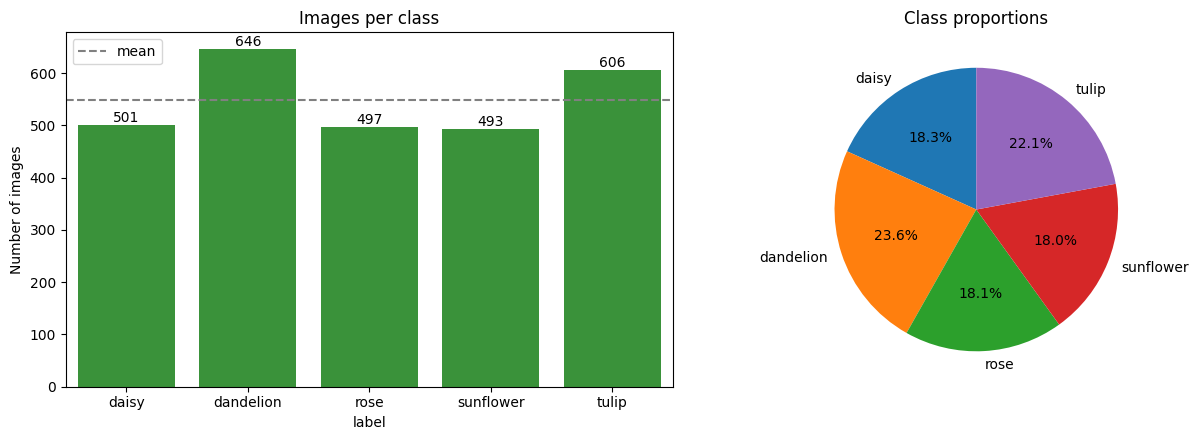

In [ ]:
# Count images per class in each split
dist = pd.DataFrame({
    "Total": df["label"].value_counts(),
    "Train": train_df["label"].value_counts(),
    "Val":   val_df["label"].value_counts(),
    "Test":  test_df["label"].value_counts(),
}).loc[CLASS_NAMES]
dist["% of total"] = (dist["Total"] / dist["Total"].sum() * 100).round(1)
display(dist)

# Imbalance ratio = biggest class / smallest class
ratio = dist["Total"].max() / dist["Total"].min()
print(f"Largest: {dist['Total'].idxmax()} ({dist['Total'].max()}) | "
      f"Smallest: {dist['Total'].idxmin()} ({dist['Total'].min()}) | Ratio: {ratio:.2f}")
print("Rule of thumb: <1.5 balanced, 1.5-3 mild imbalance, >3 significant imbalance")

# Bar chart + pie chart
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=dist.index, y=dist["Total"], ax=ax[0], color="tab:green")
ax[0].axhline(dist["Total"].mean(), ls="--", c="grey", label="mean")
for i, v in enumerate(dist["Total"]):
    ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_title("Images per class"); ax[0].set_ylabel("Number of images"); ax[0].legend()
ax[1].pie(dist["Total"], labels=dist.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class proportions")
plt.tight_layout(); plt.savefig("screenshots/01_class_distribution.png", dpi=150); plt.show()

### 1.1.4 Sample images and image sizes
Show five sample images per class and check the original image sizes.

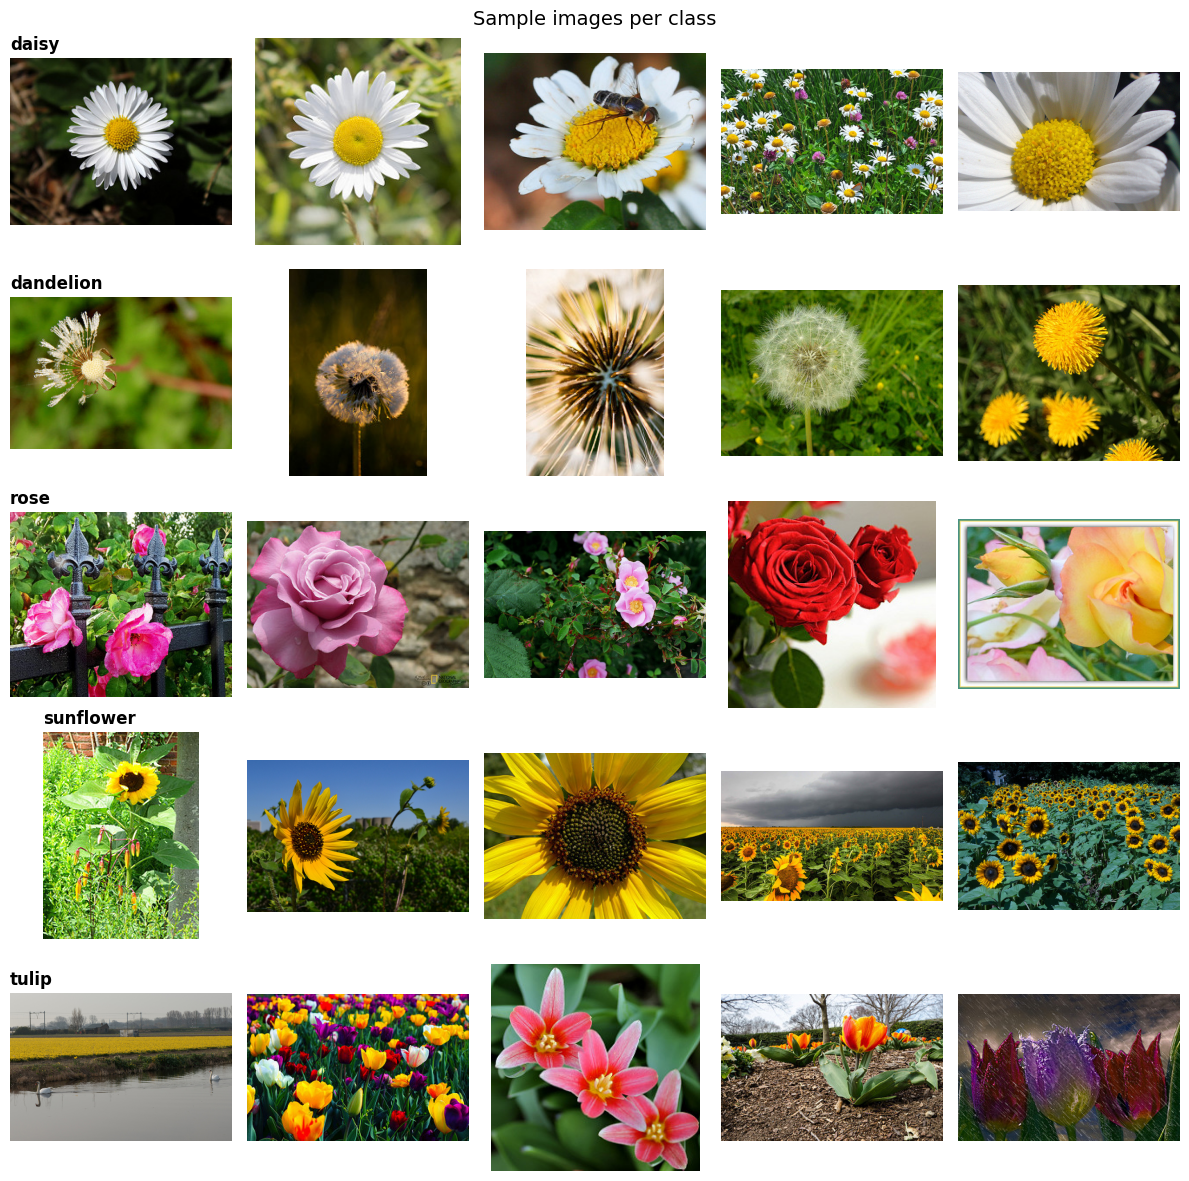

In [ ]:
N = 5  # images per class
fig, axes = plt.subplots(NUM_CLASSES, N, figsize=(N * 2.4, NUM_CLASSES * 2.4))
for r, cls in enumerate(CLASS_NAMES):
    sample = df[df["label"] == cls].sample(N, random_state=SEED)["path"]   # random 5 from this class
    for c, p in enumerate(sample):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Sample images per class", fontsize=14)
plt.tight_layout(); plt.savefig("screenshots/02_sample_images.png", dpi=150); plt.show()

Width:  143–1024 px (median 320)
Height: 159–441 px (median 240)


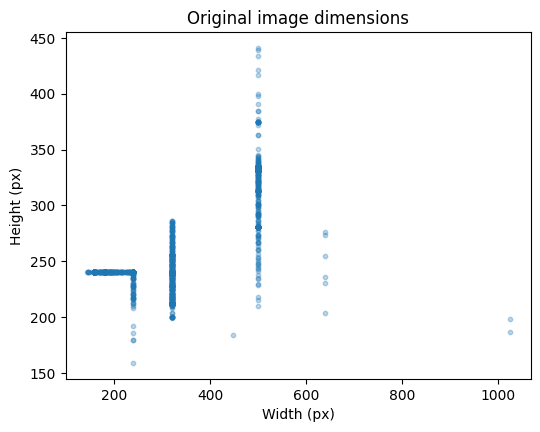

In [ ]:
# Check the original sizes of every image
sizes = [Image.open(p).size for p in df["path"]]
w, h = zip(*sizes)
print(f"Width:  {min(w)}–{max(w)} px (median {int(np.median(w))})")
print(f"Height: {min(h)}–{max(h)} px (median {int(np.median(h))})")

plt.figure(figsize=(6, 4.5))
plt.scatter(w, h, alpha=0.3, s=10)
plt.xlabel("Width (px)"); plt.ylabel("Height (px)")
plt.title("Original image dimensions")
plt.savefig("screenshots/03_image_sizes.png", dpi=150); plt.show()

### 1.1.5 Pre-processing
Resize to 128×128, normalise to 0–1, one-hot encode the labels, calculate class weights and set up data augmentation for the CNN.

In [ ]:
IMG_SIZE    = 128
BATCH_SIZE  = 32
AUTOTUNE    = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)  # force 3 colour channels (RGB)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))                     # resize to 128x128
    img = tf.cast(img, tf.float32) / 255.0                               # normalise pixels 0-255 -> 0-1
    return img, tf.one_hot(label, NUM_CLASSES)                           # label 2 -> [0,0,1,0,0]

def make_ds(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["y"].values))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()         # load once, keep in memory
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED)                           # shuffle training data only
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)                       # prepare next batch while training

train_ds = make_ds(train_df, shuffle=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)
y_test   = test_df["y"].values   # true labels, needed for evaluation later

xb, yb = next(iter(train_ds))
print("Batch shape:", xb.shape)                                          # expect (32, 128, 128, 3)
print("Pixel range:", float(tf.reduce_min(xb)), "to", float(tf.reduce_max(xb)))  # expect 0.0 to 1.0

Batch shape: (32, 128, 128, 3)
Pixel range: 0.0 to 1.0


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["y"])
CLASS_WEIGHTS = dict(enumerate(cw))
print({CLASS_NAMES[k]: round(v, 3) for k, v in CLASS_WEIGHTS.items()})

{'daisy': np.float64(1.094), 'dandelion': np.float64(0.85), 'rose': np.float64(1.103), 'sunflower': np.float64(1.113), 'tulip': np.float64(0.906)}


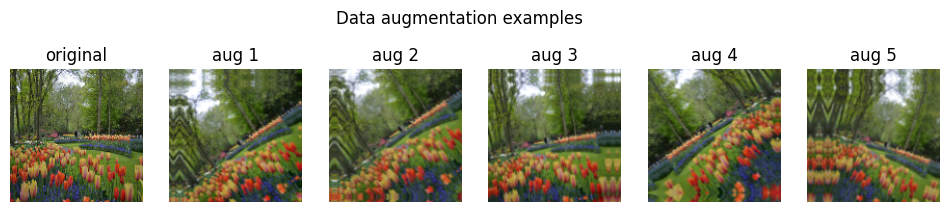

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),       # mirror left/right
    layers.RandomRotation(0.10),           # rotate up to ±36°
    layers.RandomZoom(0.15),               # zoom in/out up to 15%
    layers.RandomTranslation(0.10, 0.10),  # shift up to 10%
    layers.RandomContrast(0.15),           # vary lighting/contrast
], name="data_augmentation")

# Show one training image with 5 random augmentations
img = xb[0]
plt.figure(figsize=(12, 2.6))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    out = img if i == 0 else data_augmentation(tf.expand_dims(img, 0), training=True)[0]
    plt.imshow(np.clip(out, 0, 1)); plt.axis("off")
    plt.title("original" if i == 0 else f"aug {i}")
plt.suptitle("Data augmentation examples")
plt.savefig("screenshots/04_augmentation.png", dpi=150); plt.show()

## 1.2 Deep Learning Model Development

### 1.2.1 Training setup
Shared training and plotting functions, so every model uses the same settings (Adam, learning rate 0.001, batch size 32, up to 50 epochs with EarlyStopping).

In [ ]:
EPOCHS = int(os.environ.get("EPOCHS", 50))
results = {}   # stores each model, its history and timings for the comparison later

def train_model(model, name, epochs=EPOCHS):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        # stop when val_loss hasn't improved for 8 epochs, and roll back to the best epoch
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        # halve the learning rate if val_loss stalls for 3 epochs
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ]
    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     callbacks=callbacks, class_weight=CLASS_WEIGHTS, verbose=2)
    t = time.time() - start
    results[name] = {"model": model, "history": hist.history, "train_time_s": t,
                     "epochs_run": len(hist.history["loss"]), "params": model.count_params()}
    print(f"\n{name}: {len(hist.history['loss'])} epochs in {t:.1f}s")

def plot_history(name):
    h = results[name]["history"]
    best = int(np.argmin(h["val_loss"]))          # epoch with the lowest validation loss
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for a, m in zip(ax, ["accuracy", "loss"]):
        a.plot(range(1, len(h[m]) + 1), h[m], label=f"train {m}")
        a.plot(range(1, len(h[m]) + 1), h[f"val_{m}"], label=f"validation {m}")
        a.axvline(best + 1, ls="--", c="grey", label=f"best epoch ({best + 1})")
        a.set_xlabel("Epoch"); a.set_ylabel(m.capitalize()); a.legend(); a.grid(alpha=.3)
        a.set_title(f"{name} – {m}")
    plt.tight_layout(); plt.savefig(f"screenshots/curves_{name.replace(' ', '_')}.png", dpi=150); plt.show()
    gap = h["accuracy"][best] - h["val_accuracy"][best]
    print(f"Best epoch {best + 1}: train acc {h['accuracy'][best]:.3f} | val acc {h['val_accuracy'][best]:.3f} "
          f"| gap {gap:.3f} ({'overfitting' if gap > 0.10 else 'small gap'})")

### 1.2.2 Model 1 – ANN
Flatten → Dense 512 → 256 → 128 → Softmax, with Batch Normalisation and Dropout.

Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    25,166,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,334,789 (96.64 MB)

 Trainable params: 25,332,997 (96.64 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/50
60/60 - 10s - 165ms/step - accuracy: 0.2990 - loss: 1.9508 - val_accuracy: 0.3066 - val_loss: 2.0958 - learning_rate: 0.0010
Epoch 2/50
60/60 - 2s - 39ms/step - accuracy: 0.3755 - loss: 1.5889 - val_accuracy: 0.3552 - val_loss: 1.6679 - learning_rate: 0.0010
Epoch 3/50
60/60 - 1s - 17ms/step - accuracy: 0.4073 - loss: 1.5211 - val_accuracy: 0.4015 - val_loss: 1.3738 - learning_rate: 0.0010
Epoch 4/50
60/60 - 1s - 21ms/step - accuracy: 0.4193 - loss: 1.3903 - val_accuracy: 0.3869 - val_loss: 1.3392 - learning_rate: 0.0010
Epoch 5/50
60/60 - 1s - 12ms/step - accuracy: 0.4359 - loss: 1.3338 - val_accuracy: 0.4161 - val_loss: 1.3226 - learning_rate: 0.0010
Epoch 6/50
60/60 - 1s - 10ms/step - accuracy: 0.4635 - loss: 1.3026 - val_accuracy: 0.4234 - val_loss: 1.4136 - learning_rate: 0.0010
Epoch 7/50
60/60 - 1s - 12ms/step - accuracy: 0.4792 - loss: 1.2740 - val_accuracy: 0.4574 - val_loss: 1.3203 - learning_rate: 0.0010
Epoch 8/50
60/60 - 1s - 10ms/step - accuracy: 0.5031 - loss:

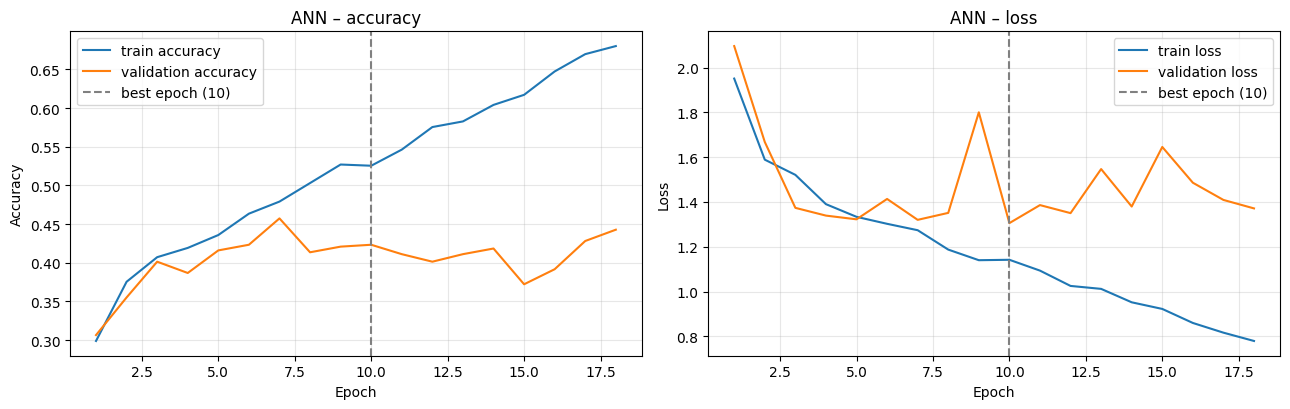

Best epoch 10: train acc 0.526 | val acc 0.423 | gap 0.102 (overfitting)


In [ ]:
def build_ann():
    return keras.Sequential([
        layers.Input((IMG_SIZE, IMG_SIZE, 3)),
        layers.Flatten(),                                   # 128x128x3 -> 49,152 values
        layers.Dense(512, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.4),
        layers.Dense(256, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.4),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),    # 5 class probabilities
    ], name="ANN")

ann = build_ann()
ann.summary()
train_model(ann, "ANN")
plot_history("ANN")

### 1.2.3 Model 2a – Baseline CNN
A simple CNN with no regularisation, trained to check for overfitting.

Model: "CNN_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,325 (16.36 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
60/60 - 15s - 251ms/step - accuracy: 0.3693 - loss: 1.4042 - val_accuracy: 0.4453 - val_loss: 1.2915 - learning_rate: 0.0010
Epoch 2/50
60/60 - 1s - 21ms/step - accuracy: 0.5620 - loss: 1.0549 - val_accuracy: 0.5791 - val_loss: 1.0943 - learning_rate: 0.0010
Epoch 3/50
60/60 - 1s - 21ms/step - accuracy: 0.6604 - loss: 0.8967 - val_accuracy: 0.5961 - val_loss: 1.0673 - learning_rate: 0.0010
Epoch 4/50
60/60 - 1s - 21ms/step - accuracy: 0.7365 - loss: 0.6885 - val_accuracy: 0.5912 - val_loss: 1.0528 - learning_rate: 0.0010
Epoch 5/50
60/60 - 1s - 21ms/step - accuracy: 0.7995 - loss: 0.5300 - val_accuracy: 0.6034 - val_loss: 1.1323 - learning_rate: 0.0010
Epoch 6/50
60/60 - 1s - 21ms/step - accuracy: 0.8651 - loss: 0.3816 - val_accuracy: 0.5791 - val_loss: 1.3640 - learning_rate: 0.0010
Epoch 7/50
60/60 - 1s - 21ms/step - accuracy: 0.9203 - loss: 0.2505 - val_accuracy: 0.5985 - val_loss: 1.3749 - learning_rate: 0.0010
Epoch 8/50
60/60 - 1s - 22ms/step - accuracy: 0.9641 - loss:

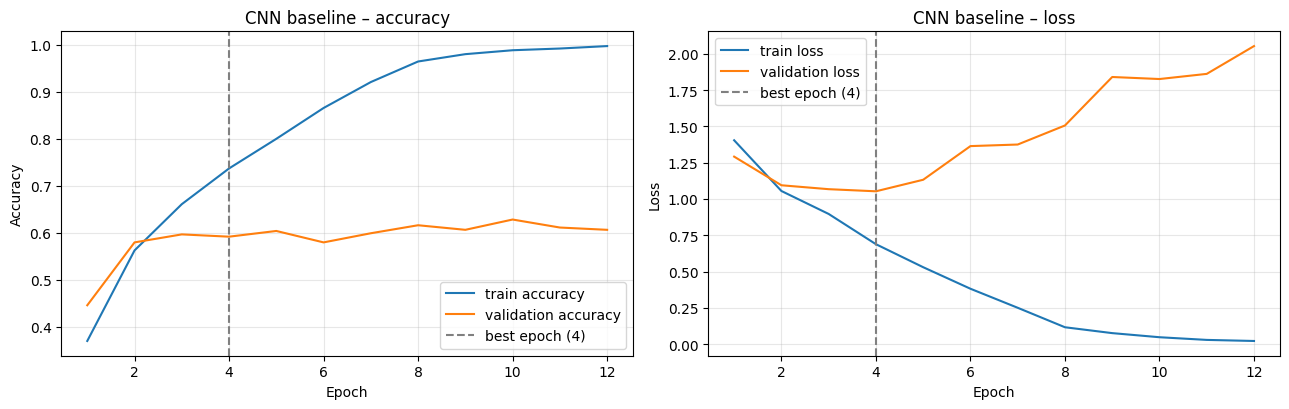

Best epoch 4: train acc 0.736 | val acc 0.591 | gap 0.145 (overfitting)


In [ ]:
def build_cnn_baseline():
    return keras.Sequential([
        layers.Input((IMG_SIZE, IMG_SIZE, 3)),
        layers.Conv2D(32, 3, activation="relu", padding="same"),  layers.MaxPooling2D(),  # edges/colours
        layers.Conv2D(64, 3, activation="relu", padding="same"),  layers.MaxPooling2D(),  # textures
        layers.Conv2D(128, 3, activation="relu", padding="same"), layers.MaxPooling2D(),  # shapes/parts
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="CNN_baseline")

cnn_base = build_cnn_baseline()
cnn_base.summary()
train_model(cnn_base, "CNN baseline")
plot_history("CNN baseline")

### 1.2.4 Model 2b – Final CNN
Four convolution blocks with data augmentation, Batch Normalisation, Dropout, L2 and Global Average Pooling to reduce overfitting.

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 617,829 (2.36 MB)

 Trainable params: 616,421 (2.35 MB)

 Non-trainable params: 1,408 (5.50 KB)

Epoch 1/50
60/60 - 16s - 270ms/step - accuracy: 0.4526 - loss: 1.3642 - val_accuracy: 0.2360 - val_loss: 1.8237 - learning_rate: 0.0010
Epoch 2/50
60/60 - 6s - 97ms/step - accuracy: 0.5380 - loss: 1.1535 - val_accuracy: 0.2360 - val_loss: 2.2234 - learning_rate: 0.0010
Epoch 3/50
60/60 - 6s - 95ms/step - accuracy: 0.5604 - loss: 1.0841 - val_accuracy: 0.2384 - val_loss: 2.1051 - learning_rate: 0.0010
Epoch 4/50
60/60 - 6s - 98ms/step - accuracy: 0.5969 - loss: 0.9951 - val_accuracy: 0.2652 - val_loss: 1.9468 - learning_rate: 0.0010
Epoch 5/50
60/60 - 6s - 97ms/step - accuracy: 0.6464 - loss: 0.9086 - val_accuracy: 0.2822 - val_loss: 1.9927 - learning_rate: 5.0000e-04
Epoch 6/50
60/60 - 6s - 97ms/step - accuracy: 0.6552 - loss: 0.8942 - val_accuracy: 0.3139 - val_loss: 1.8693 - learning_rate: 5.0000e-04
Epoch 7/50
60/60 - 6s - 98ms/step - accuracy: 0.6495 - loss: 0.9210 - val_accuracy: 0.4453 - val_loss: 1.4578 - learning_rate: 5.0000e-04
Epoch 8/50
60/60 - 6s - 97ms/step - accuracy: 0.

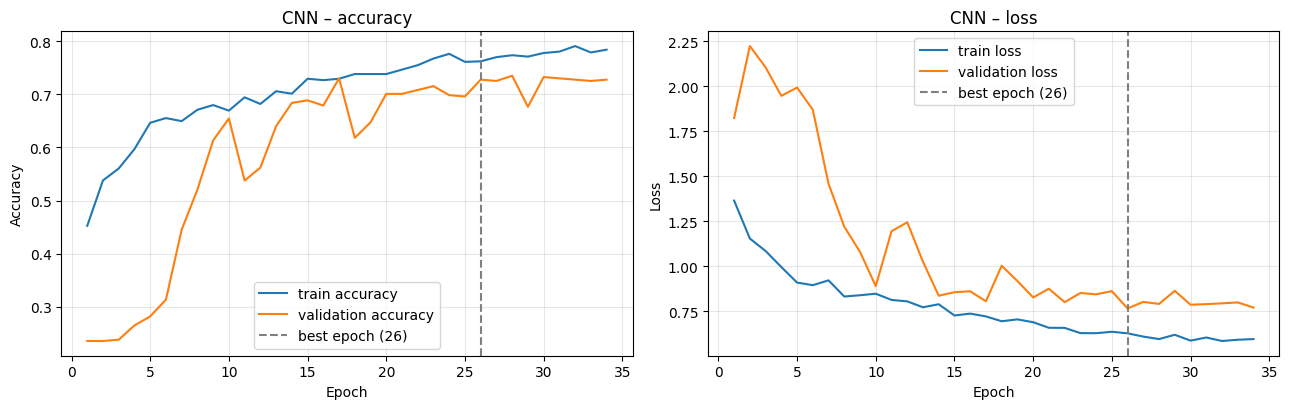

Best epoch 26: train acc 0.762 | val acc 0.727 | gap 0.034 (small gap)


In [ ]:
def conv_block(x, filters, n_convs, drop):
    for _ in range(n_convs):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)  # BN makes bias unnecessary
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(drop)(x)

def build_cnn():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inp)            # only active during training
    x = conv_block(x, 32, 2, 0.20)
    x = conv_block(x, 64, 2, 0.25)
    x = conv_block(x, 128, 2, 0.30)
    x = conv_block(x, 256, 1, 0.30)
    x = layers.GlobalAveragePooling2D()(x)  # replaces Flatten -> far fewer parameters
    x = layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="CNN")

cnn = build_cnn()
cnn.summary()
train_model(cnn, "CNN")
plot_history("CNN")

## 1.3 Model Evaluation and Comparison

### 1.3.1 Overfitting analysis
Training vs validation curves and the train–validation gap for the ANN and final CNN.

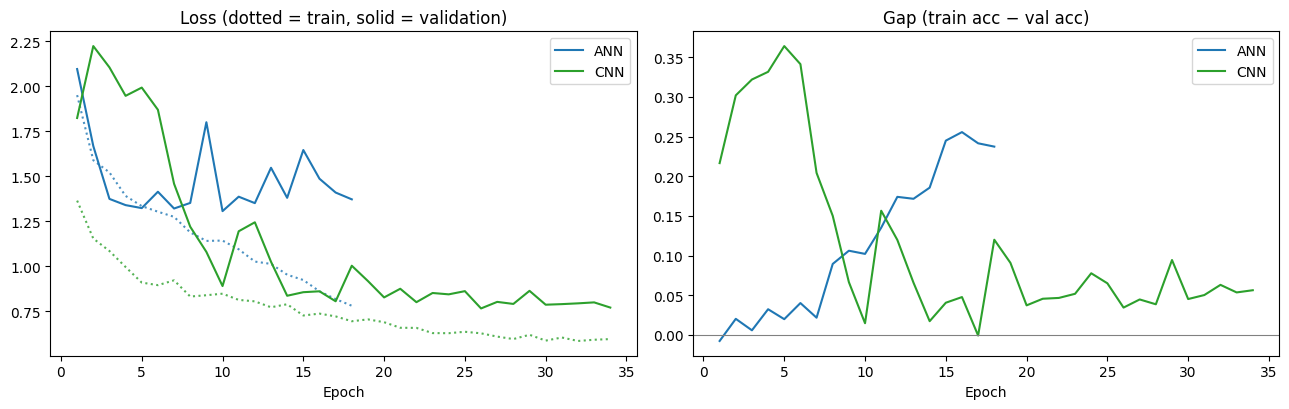

,Model,Epochs run,Best epoch,Train acc,Val acc,Gap,Max train acc,Final val loss,Min val loss
0,ANN,18,10,0.526,0.423,0.102,0.680,1.371,1.306
1,CNN,34,26,0.762,0.727,0.034,0.791,0.770,0.765


In [ ]:
# Compare validation loss and the train-val gap for the ANN and final CNN
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, c in [("ANN", "tab:blue"), ("CNN", "tab:green")]:
    h = results[name]["history"]; ep = range(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], c=c, ls=":", alpha=.8)              # dotted = training loss
    ax[0].plot(ep, h["val_loss"], c=c, label=name)                 # solid = validation loss
    ax[1].plot(ep, np.array(h["accuracy"]) - np.array(h["val_accuracy"]), c=c, label=name)
ax[0].set_title("Loss (dotted = train, solid = validation)"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].axhline(0, c="grey", lw=.8)
ax[1].set_title("Gap (train acc − val acc)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("screenshots/05_overfitting_comparison.png", dpi=150); plt.show()

# Summary table at each model's best epoch
rows = []
for name in ["ANN", "CNN"]:
    h = results[name]["history"]; b = int(np.argmin(h["val_loss"]))
    rows.append({"Model": name, "Epochs run": len(h["loss"]), "Best epoch": b + 1,
                 "Train acc": h["accuracy"][b], "Val acc": h["val_accuracy"][b],
                 "Gap": h["accuracy"][b] - h["val_accuracy"][b],
                 "Max train acc": max(h["accuracy"]), "Final val loss": h["val_loss"][-1],
                 "Min val loss": min(h["val_loss"])})
overfit_table = pd.DataFrame(rows).round(3)
display(overfit_table)

### 1.3.2 Test set results
Accuracy, precision, recall, F1-score, confusion matrix and ROC curves on the 412 test images.

In [ ]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, roc_curve, auc, ConfusionMatrixDisplay)
from sklearn.preprocessing import label_binarize

def evaluate_model(name):
    model = results[name]["model"]
    loss, _ = model.evaluate(test_ds, verbose=0)
    start = time.time()
    probs = model.predict(test_ds, verbose=0)                    # class probabilities
    infer_ms = (time.time() - start) / len(y_test) * 1000        # prediction time per image
    preds = probs.argmax(1)                                      # most likely class
    p, r, f, _ = precision_recall_fscore_support(y_test, preds, average="macro", zero_division=0)
    results[name].update({"probs": probs, "preds": preds, "infer_ms": infer_ms, "test_loss": loss,
                          "acc": accuracy_score(y_test, preds), "precision": p, "recall": r, "f1": f})

    print(f"===== {name} – TEST SET =====")
    print(f"Accuracy: {results[name]['acc']:.4f} | Test loss: {loss:.4f}\n")
    print(classification_report(y_test, preds, target_names=CLASS_NAMES, digits=3, zero_division=0))
    rep = classification_report(y_test, preds, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    pd.DataFrame(rep).T.round(3).to_csv(f"screenshots/report_{name.replace(' ', '_')}.csv")

    # Confusion matrix (counts) + normalised version (each row = recall for that class)
    cm = confusion_matrix(y_test, preds)
    results[name]["cm"] = cm
    fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
    ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASS_NAMES).plot(
        ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
    ax[0].set_title(f"{name} – confusion matrix"); ax[1].set_title(f"{name} – normalised")
    for a in ax[:2]: a.tick_params(axis="x", rotation=45)

    # ROC curves, one-vs-rest for each class
    y_bin = label_binarize(y_test, classes=range(NUM_CLASSES))
    aucs = []
    for i, cls in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i]); a = auc(fpr, tpr); aucs.append(a)
        ax[2].plot(fpr, tpr, label=f"{cls} (AUC={a:.3f})")
    ax[2].plot([0, 1], [0, 1], ":", c="grey")
    ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
    ax[2].set_title(f"{name} – ROC curves"); ax[2].legend(fontsize=8, loc="lower right")
    results[name]["macro_auc"] = float(np.mean(aucs)); results[name]["class_auc"] = aucs
    print(f"Macro AUC: {results[name]['macro_auc']:.4f}")

    plt.tight_layout(); plt.savefig(f"screenshots/eval_{name.replace(' ', '_')}.png", dpi=150); plt.show()

===== ANN – TEST SET =====
Accuracy: 0.4442 | Test loss: 1.3269

              precision    recall  f1-score   support

       daisy      0.476     0.267     0.342        75
   dandelion      0.427     0.546     0.480        97
        rose      0.443     0.520     0.479        75
   sunflower      0.484     0.595     0.533        74
       tulip      0.403     0.297     0.342        91

    accuracy                          0.444       412
   macro avg      0.447     0.445     0.435       412
weighted avg      0.444     0.444     0.434       412

Macro AUC: 0.7710


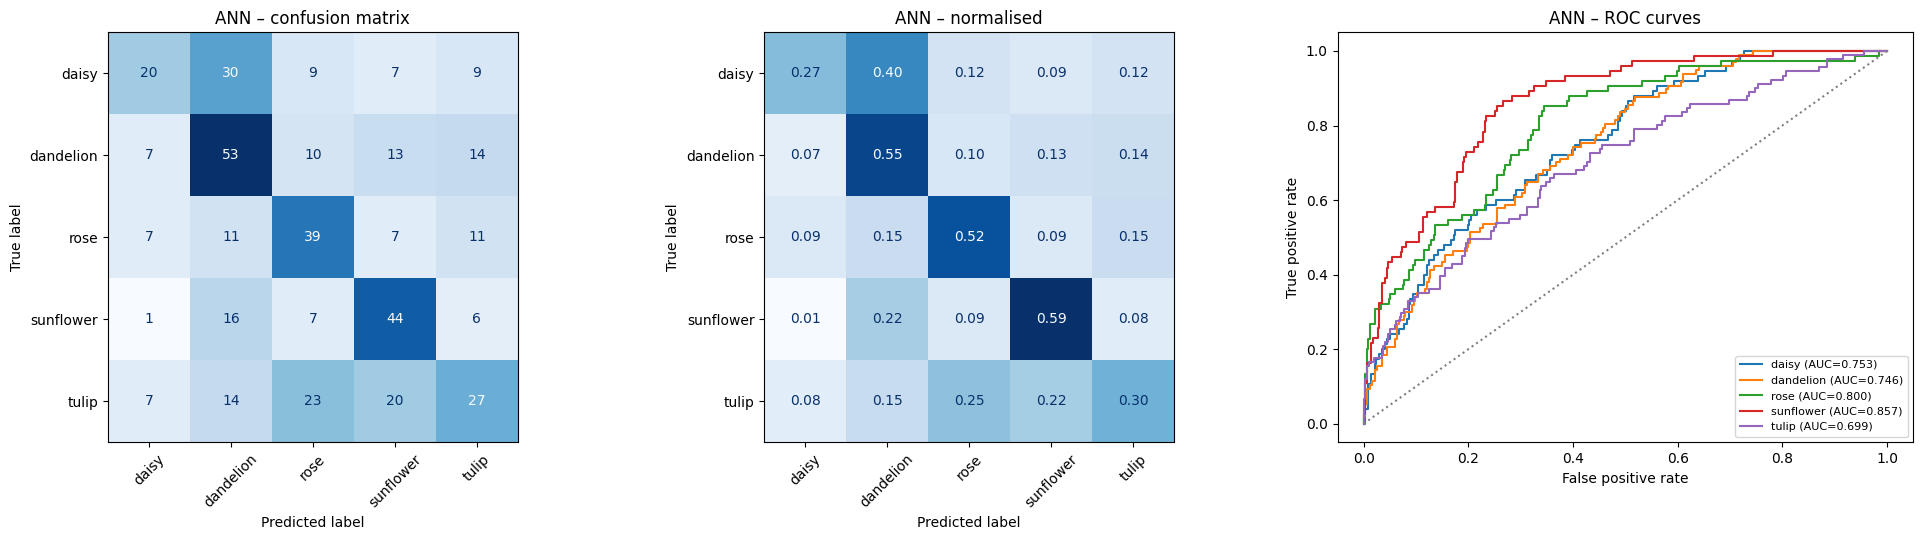

In [ ]:
evaluate_model("ANN")

===== CNN – TEST SET =====
Accuracy: 0.7549 | Test loss: 0.7661

              precision    recall  f1-score   support

       daisy      0.768     0.840     0.803        75
   dandelion      0.878     0.742     0.804        97
        rose      0.587     0.813     0.682        75
   sunflower      0.759     0.851     0.803        74
       tulip      0.852     0.571     0.684        91

    accuracy                          0.755       412
   macro avg      0.769     0.764     0.755       412
weighted avg      0.778     0.755     0.755       412

Macro AUC: 0.9318


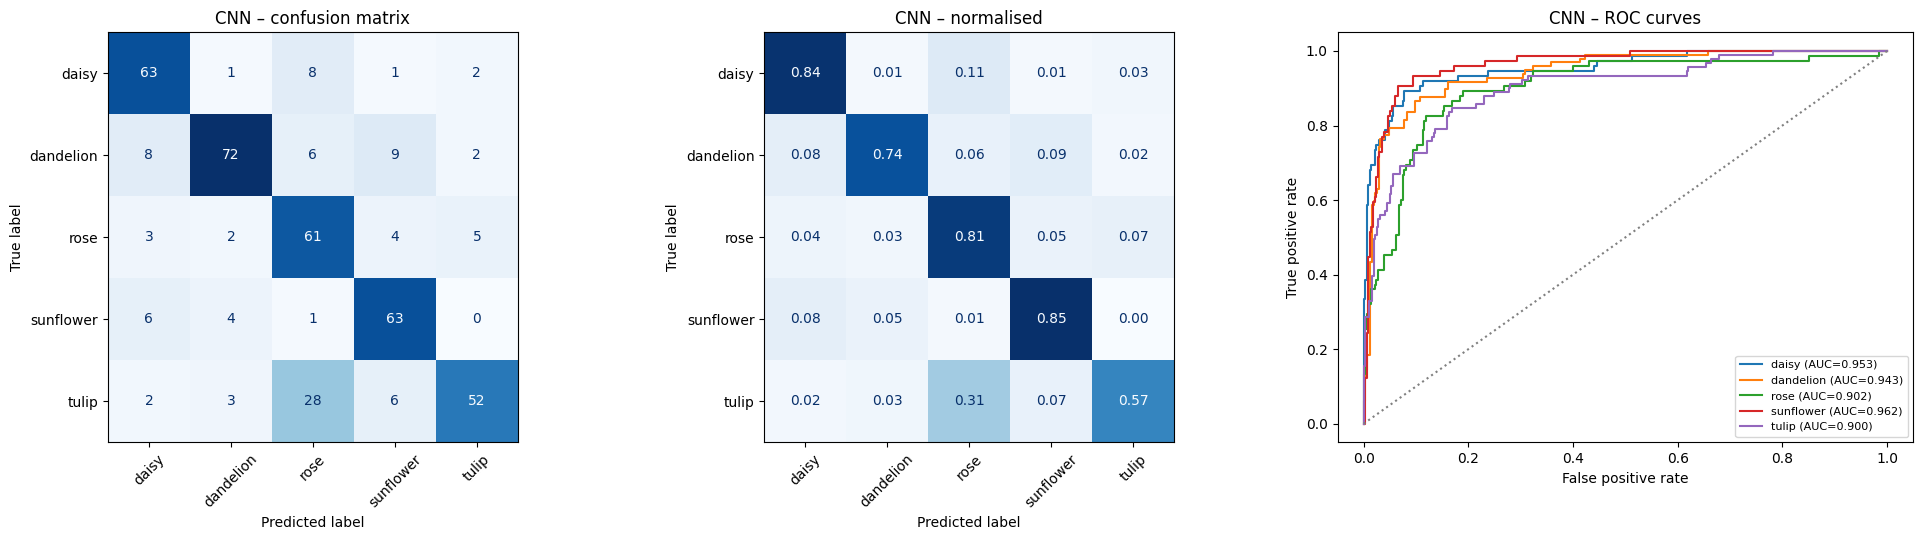

In [ ]:
evaluate_model("CNN")

### 1.3.3 ANN vs CNN comparison
Side-by-side comparison of the test metrics, parameters and training time.

,Test accuracy,Test loss,Macro precision,Macro recall,Macro F1,Macro AUC,Parameters,Size (MB),Epochs run,Train time (s),Time per epoch (s),Inference (ms/img)
Model,,,,,,,,,,,,
ANN,0.4442,1.3269,0.4467,0.4449,0.4350,0.7710,25334789,96.6446,18,23.8006,1.3223,1.6204
CNN,0.7549,0.7661,0.7689,0.7637,0.7551,0.9318,617829,2.3568,34,214.6050,6.3119,1.3396


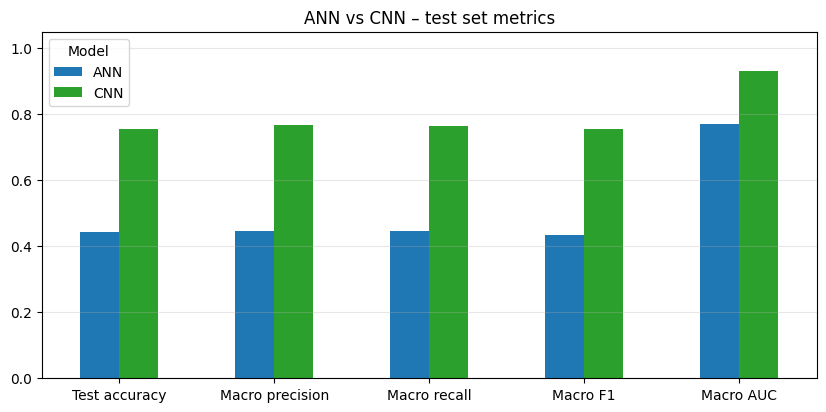

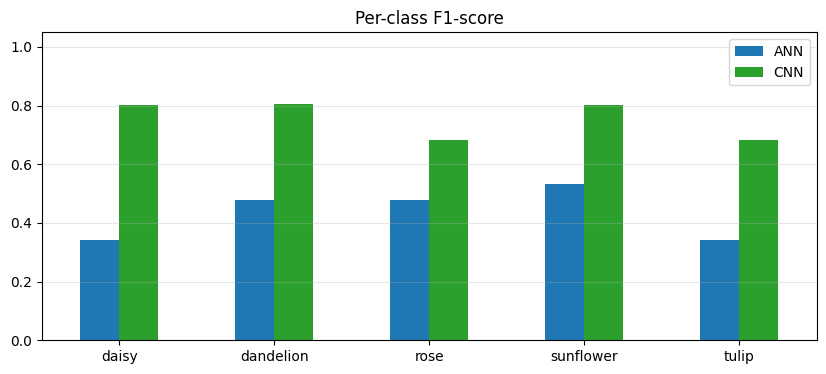

In [ ]:
comp = pd.DataFrame([{
    "Model": n,
    "Test accuracy": r["acc"], "Test loss": r["test_loss"], "Macro precision": r["precision"],
    "Macro recall": r["recall"], "Macro F1": r["f1"], "Macro AUC": r["macro_auc"],
    "Parameters": r["params"], "Size (MB)": r["params"] * 4 / 1024**2,
    "Epochs run": r["epochs_run"], "Train time (s)": r["train_time_s"],
    "Time per epoch (s)": r["train_time_s"] / r["epochs_run"], "Inference (ms/img)": r["infer_ms"],
} for n, r in results.items() if n in ("ANN", "CNN")]).set_index("Model")
display(comp.round(4))
comp.round(4).to_csv("screenshots/model_comparison.csv")

# Bar chart of the main metrics
metrics = ["Test accuracy", "Macro precision", "Macro recall", "Macro F1", "Macro AUC"]
comp.loc[["ANN", "CNN"], metrics].T.plot(kind="bar", figsize=(10, 4.5), rot=0, color=["tab:blue", "tab:green"])
plt.ylim(0, 1.05); plt.title("ANN vs CNN – test set metrics"); plt.grid(axis="y", alpha=.3)
plt.savefig("screenshots/06_ann_vs_cnn_metrics.png", dpi=150, bbox_inches="tight"); plt.show()

# Per-class F1 – which flowers each model finds hard
f1_ann = precision_recall_fscore_support(y_test, results["ANN"]["preds"], zero_division=0)[2]
f1_cnn = precision_recall_fscore_support(y_test, results["CNN"]["preds"], zero_division=0)[2]
pd.DataFrame({"ANN": f1_ann, "CNN": f1_cnn}, index=CLASS_NAMES).plot(
    kind="bar", figsize=(10, 4), rot=0, color=["tab:blue", "tab:green"])
plt.ylim(0, 1.05); plt.title("Per-class F1-score"); plt.grid(axis="y", alpha=.3)
plt.savefig("screenshots/07_per_class_f1.png", dpi=150, bbox_inches="tight"); plt.show()

CNN misclassified 101 of 412 test images


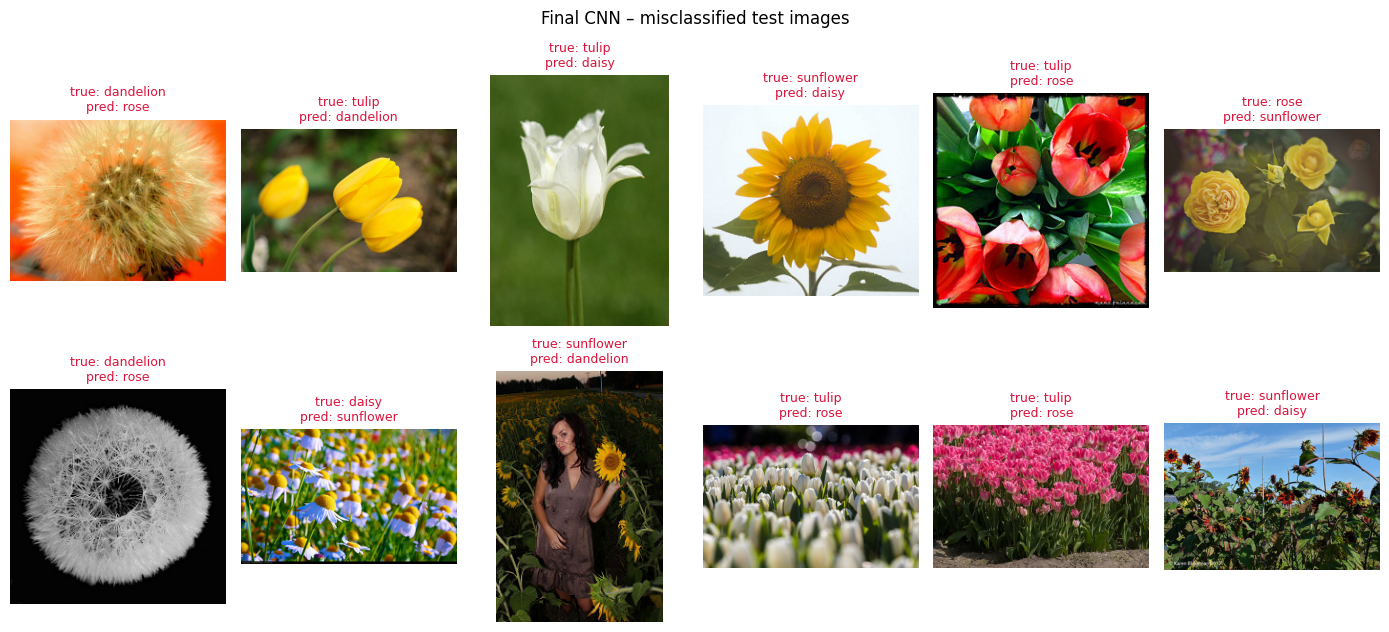

In [ ]:
# Some of the test images the final CNN still got wrong
wrong = np.where(results["CNN"]["preds"] != y_test)[0]
print(f"CNN misclassified {len(wrong)} of {len(y_test)} test images")
show = wrong[:12]
rows_n = int(np.ceil(len(show) / 6))
plt.figure(figsize=(14, 3.2 * rows_n))
for i, idx in enumerate(show):
    plt.subplot(rows_n, 6, i + 1)
    plt.imshow(Image.open(test_df["path"].iloc[idx]).convert("RGB")); plt.axis("off")
    plt.title(f"true: {CLASS_NAMES[y_test[idx]]}\npred: {CLASS_NAMES[results['CNN']['preds'][idx]]}",
              fontsize=9, color="crimson")
plt.suptitle("Final CNN – misclassified test images"); plt.tight_layout()
plt.savefig("screenshots/08_cnn_errors.png", dpi=150); plt.show()

## 1.4 Critical Analysis and Discussion
The final CNN reached 75.49% test accuracy compared with 44.42% for the ANN, using about 41 times fewer parameters but taking longer to train. Its main errors were tulips predicted as roses. The full discussion is in report section 2.6.

In [ ]:
# Save the two main models (used in the demo video)
os.makedirs("saved_models", exist_ok=True)
for n in ["ANN", "CNN"]:
    results[n]["model"].save(f"saved_models/{n}.keras")
print("Models saved to saved_models/, figures and tables saved to screenshots/")

Models saved to saved_models/, figures and tables saved to screenshots/
